<a href="https://colab.research.google.com/github/marcelosantosjunior2027/IFOOD_GENAI_PORTIF-LIO/blob/main/LOG%C3%8DSTICA_PROJ_FINAL_%C3%93LEO_G%C3%81S%5B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dimensionamento do sequenciamento estrutural do projeto de logística

AQUI ESTÁ A ARQUITETURA DO REPOSITÓRIO

offshore-oil-gas-logistics/
├── src/
│   ├── __init__.py
│   ├── domain.py          # Estruturas de dados: FPSOs, Shuttle Tankers, Terminais, Metocean
│   ├── metocean.py        # Simulador estocástico de ondas (Hs), ventos e janelas operacionais
│   ├── optimizer.py       # Motor de despacho e otimização (MILP / Heurística de Criticidade)
│   └── visualizer.py      # Geração de dashboards 2D, rede espacial 3D e operação 4D
├── tests/
│   └── test_logistics.py  # Testes unitários de restrições físicas e prevenção de shut-in
├── main.py                # Orquestrador da simulação de 30 dias (720 horas)
├── requirements.txt
└── README.md

In [12]:
# AUTOR : MARCELO DE OLIVEIRA SANTOS JUNIOR
# Entidades Físicas e Restrições Operacionais



from dataclasses import dataclass, field
from typing import List


@dataclass
class FPSO:
    name: str
    lat: float
    lon: float
    water_depth_m: float
    storage_capacity_bbl: float
    current_inventory_bbl: float
    production_rate_bph: float
    max_offloading_rate_bph: float
    max_wave_height_m: float = 3.2
    shut_in_hours: int = 0
    total_lost_bbl: float = 0.0
    inventory_history: List[float] = field(default_factory=list)

    @property
    def fill_ratio(self) -> float:
        return self.current_inventory_bbl / self.storage_capacity_bbl

    @property
    def hours_to_full(self) -> float:
        remaining = self.storage_capacity_bbl - self.current_inventory_bbl
        return remaining / max(self.production_rate_bph, 1e-6)


@dataclass
class ShuttleTanker:
    name: str
    capacity_bbl: float
    speed_knots: float
    charter_cost_usd_day: float
    fuel_cost_usd_nm: float
    lat: float
    lon: float
    cargo_bbl: float = 0.0
    status: str = "IDLE"  # IDLE, TRANSIT_TO_FPSO, OFFLOADING, TRANSIT_TO_TERMINAL, DISCHARGING
    target_name: str = ""
    eta_hours: float = 0.0
    total_cost_usd: float = 0.0
    route_history: List[tuple] = field(default_factory=list)


@dataclass
class CoastalTerminal:
    name: str
    lat: float
    lon: float
    storage_capacity_bbl: float
    current_inventory_bbl: float
    pipeline_outflow_bph: float
    max_discharge_rate_bph: float
    inventory_history: List[float] = field(default_factory=list)

In [13]:
# AUTOR : MARCELO DE OLIVEIRA SANTOS JUNIOR
# Condições Oceanográficas e Janelas de Operação


import numpy as np


class MetoceanSimulator:
    """Modela altura significativa de onda (Hs) com persistência temporal (processo AR(1))."""

    def __init__(self, hours: int = 720, seed: int = 42):
        self.hours = hours
        self.rng = np.random.default_rng(seed)
        self.wave_height_m = self._generate_wave_series()

    def _generate_wave_series(self) -> np.ndarray:
        hs = np.zeros(self.hours)
        hs[0] = 1.8
        phi = 0.94  # Alta autocorrelação horária típica do Atlântico Sul

        for t in range(1, self.hours):
            # Ciclos de frentes frias a cada ~140 horas
            storm_forcing = 1.1 * np.sin(2 * np.pi * t / 145.0)
            shock = self.rng.normal(0.0, 0.22)
            hs[t] = 1.9 + phi * (hs[t - 1] - 1.9) + 0.12 * storm_forcing + shock

        return np.clip(hs, 0.7, 5.2)

    def can_operate(self, hour: int, max_hs_limit: float) -> bool:
        return bool(self.wave_height_m[hour] <= max_hs_limit)

In [14]:
# AUTOR : MARCELO DE OLIVEIRA SANTOS JUNIOR
# Motor de Despacho, Alívio e Escoamento Midstream

import math
from typing import List
# Removidas as importações do pacote local fictício 'src'


def haversine_nm(lat1: float, lon1: float, lat2: float, lon2: float) -> float:
    """Calcula distância marítima em milhas náuticas (NM)."""
    r_nm = 3440.065
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dp = math.radians(lat2 - lat1)
    dl = math.radians(lon2 - lon1)
    a = math.sin(dp / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2) ** 2
    return 2 * r_nm * math.atan2(math.sqrt(a), math.sqrt(1 - a))


class OffshoreLogisticsEngine:
    """Orquestra produção, alívio dinâmico DP2, restrições climáticas e dutos terrestres."""

    def __init__(
        self,
        fpsos: List[FPSO],
        tankers: List[ShuttleTanker],
        terminal: CoastalTerminal,
        metocean: MetoceanSimulator,
    ):
        self.fpsos = fpsos
        self.tankers = tankers
        self.terminal = terminal
        self.metocean = metocean

    def step(self, hour: int) -> None:
        self._update_production(hour)
        self._dispatch_idle_tankers(hour)
        self._advance_fleet(hour)
        self._update_terminal()

    def _update_production(self, hour: int) -> None:
        for fpso in self.fpsos:
            new_inv = fpso.current_inventory_bbl + fpso.production_rate_bph
            if new_inv > fpso.storage_capacity_bbl:
                overflow = new_inv - fpso.storage_capacity_bbl
                fpso.current_inventory_bbl = fpso.storage_capacity_bbl
                fpso.shut_in_hours += 1
                fpso.total_lost_bbl += overflow
            else:
                fpso.current_inventory_bbl = new_inv
            fpso.inventory_history.append(fpso.current_inventory_bbl)

    def _dispatch_idle_tankers(self, hour: int) -> None:
        # Prioriza FPSOs com menor tempo até capacidade máxima (risco de shut-in)
        assigned_fpsos = {t.target_name for t in self.tankers if t.status in ("TRANSIT_TO_FPSO", "OFFLOADING")}
        critical_fpsos = sorted(
            [f for f in self.fpsos if f.fill_ratio >= 0.58 and f.name not in assigned_fpsos],
            key=lambda f: f.hours_to_full,
        )

        for fpso in critical_fpsos:
            idle_tankers = [t for t in self.tankers if t.status == "IDLE"]
            if not idle_tankers:
                break

            # Escolhe o navio aliviador mais próximo disponível
            best_tanker = min(idle_tankers, key=lambda t: haversine_nm(t.lat, t.lon, fpso.lat, fpso.lon))
            dist = haversine_nm(best_tanker.lat, best_tanker.lon, fpso.lat, fpso.lon)
            best_tanker.status = "TRANSIT_TO_FPSO"
            best_tanker.target_name = fpso.name
            best_tanker.add_hours = 0.0 # eta_hours tracking
            best_tanker.eta_hours = dist / best_tanker.speed_knots
            best_tanker.total_cost_usd += dist * best_tanker.fuel_cost_usd_nm

    def _advance_fleet(self, hour: int) -> None:
        fpso_map = {f.name: f for f in self.fpsos}

        for tanker in self.tankers:
            tanker.total_cost_usd += tanker.charter_cost_usd_day / 24.0

            if tanker.status == "TRANSIT_TO_FPSO":
                fpso = fpso_map[tanker.target_name]
                if tanker.eta_hours <= 1.0:
                    tanker.lat, tanker.lon = fpso.lat, fpso.lon
                    tanker.eta_hours = 0.0
                    tanker.status = "OFFLOADING"
                else:
                    ratio = 1.0 / tanker.eta_hours
                    tanker.lat += (fpso.lat - tanker.lat) * ratio
                    tanker.lon += (fpso.lon - tanker.lon) * ratio
                    tanker.eta_hours -= 1.0

            elif tanker.status == "OFFLOADING":
                fpso = fpso_map[tanker.target_name]
                # Bloqueio operacional por tempestade (Hs > limite DP2)
                if not self.metocean.can_operate(hour, fpso.max_wave_height_m):
                    tanker.route_history.append((hour, tanker.lat, tanker.lon, tanker.cargo_bbl, "WEATHER_HOLD"))
                    continue

                transfer = min(
                    fpso.max_offloading_rate_bph,
                    fpso.current_inventory_bbl,
                    tanker.capacity_bbl - tanker.cargo_bbl,
                )
                fpso.current_inventory_bbl -= transfer
                tanker.cargo_bbl += transfer

                if tanker.cargo_bbl >= tanker.capacity_bbl * 0.96 or fpso.current_inventory_bbl < 40_000:
                    dist = haversine_nm(tanker.lat, tanker.lon, self.terminal.lat, self.terminal.lon)
                    tanker.status = "TRANSIT_TO_TERMINAL"
                    tanker.target_name = self.terminal.name
                    tanker.eta_hours = dist / tanker.speed_knots
                    tanker.total_cost_usd += dist * tanker.fuel_cost_usd_nm

            elif tanker.status == "TRANSIT_TO_TERMINAL":
                if tanker.eta_hours <= 1.0:
                    tanker.lat, tanker.lon = self.terminal.lat, self.terminal.lon
                    tanker.eta_hours = 0.0
                    tanker.status = "DISCHARGING"
                else:
                    ratio = 1.0 / tanker.eta_hours
                    tanker.lat += (self.terminal.lat - tanker.lat) * ratio
                    tanker.lon += (self.terminal.lon - tanker.lon) * ratio
                    tanker.eta_hours -= 1.0

            elif tanker.status == "DISCHARGING":
                ullage = self.terminal.storage_capacity_bbl - self.terminal.current_inventory_bbl
                discharge = min(self.terminal.max_discharge_rate_bph, tanker.cargo_bbl, ullage)
                tanker.cargo_bbl -= discharge
                self.terminal.current_inventory_bbl += discharge

                if tanker.cargo_bbl <= 1.0:
                    tanker.cargo_bbl = 0.0
                    tanker.status = "IDLE"
                    tanker.target_name = ""

            tanker.route_history.append((hour, tanker.lat, tanker.lon, tanker.cargo_bbl, tanker.status))

    def _update_terminal(self) -> None:
        # Escoamento contínuo via oleoduto terrestre para refinarias
        outflow = min(self.terminal.current_inventory_bbl, self.terminal.pipeline_outflow_bph)
        self.terminal.current_inventory_bbl -= outflow
        self.terminal.inventory_history.append(self.terminal.current_inventory_bbl)

In [10]:
# AUTOR : MARCELO DE OLIVEIRA SANTOS JUNIOR
# Painel 2D, Batimetria 3D e Operação 4D Animada

import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from typing import List

# Removidas as importações do pacote 'src'


def render_2d_operations_dashboard(
    fpsos: List[FPSO],
    terminal: CoastalTerminal,
    metocean: MetoceanSimulator,
) -> None:
    hours = np.arange(metocean.hours)
    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
    fig.suptitle("Monitoramento Logístico Integrado — Bacia de Santos (30 Dias / 720h)", fontsize=13, fontweight="bold")

    # Painel 1: Estoque dos FPSOs vs Capacidade
    for fpso in fpsos:
        axes[0].plot(hours, np.array(fpso.inventory_history) / 1e6, lw=1.6, label=f"{fpso.name} (Lost: {fpso.total_lost_bbl:,.0f} bbl)")
    axes[0].axhline(1.6, color="red", linestyle="--", lw=1.2, label="Limite Tancagem FPSO (1.6M bbl)")
    axes[0].set_ylabel("Estoque FPSO (Milhões bbl)")
    axes[0].legend(loc="upper right", fontsize=8)
    axes[0].grid(True, alpha=0.3)

    # Painel 2: Condição Oceanográfica (Altura Significativa de Onda Hs)
    axes[1].plot(hours, metocean.wave_height_m, color="#1f77b4", lw=1.2)
    axes[1].axhline(3.2, color="darkred", linestyle="--", label="Limite Operacional Offloading DP2 (Hs = 3.2m)")
    axes[1].fill_between(hours, metocean.wave_height_m, 3.2, where=(metocean.wave_height_m > 3.2), color="red", alpha=0.3, label="Janela Fechada (Weather Hold)")
    axes[1].set_ylabel("Altura Onda Hs (m)")
    axes[1].legend(loc="upper right", fontsize=8)
    axes[1].grid(True, alpha=0.3)

    # Painel 3: Tancagem Terminal Costeiro & Escoamento Oleoduto
    axes[2].plot(hours, np.array(terminal.inventory_history) / 1e6, color="#2ca02c", lw=1.8, label=f"Terminal {terminal.name}")
    axes[2].set_ylabel("Tancagem Terminal (Milhões bbl)")
    axes[2].set_xlabel("Tempo de Operação (Horas)")
    axes[2].legend(loc="upper right", fontsize=8)
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


def render_4d_offshore_network(
    fpsos: List[FPSO],
    tankers: List[ShuttleTanker],
    terminal: CoastalTerminal,
) -> None:
    """Constrói modelo batimétrico 3D da Bacia de Santos + animação 4D da frota de alívio."""
    lon_grid = np.linspace(-45.5, -42.0, 40)
    lat_grid = np.linspace(-26.0, -23.5, 40)
    LON, LAT = np.meshgrid(lon_grid, lat_grid)

    # Modelo batimétrico realista: plataforma continental rasa perto da costa -> talude -> lâmina d'água 2200m
    dist_coast = np.sqrt((LON + 45.4) ** 2 + (LAT + 23.8) ** 2)
    DEPTH_M = -2300.0 / (1.0 + np.exp(-3.2 * (dist_coast - 1.35)))

    surface = go.Surface(
        x=LON,
        y=LAT,
        z=DEPTH_M,
        colorscale="Blues_r",
        opacity=0.65,
        showscale=False,
        name="Batimetria Bacia de Santos",
    )

    # Marcos estáticos: FPSOs (nível do mar Z=0 + risers até o fundo) e Terminal Costeiro
    fpso_trace = go.Scatter3d(
        x=[f.lon for f in fpsos],
        y=[f.lat for f in fpsos],
        z=[0.0 for _ in fpsos],
        mode="markers+text",
        text=[f.name for f in fpsos],
        textposition="top center",
        marker=dict(size=9, color="gold", symbol="diamond"),
        name="FPSOs Pré-Sal",
    )

    term_trace = go.Scatter3d(
        x=[terminal.lon],
        y=[terminal.lat],
        z=[10.0],
        mode="markers+text",
        text=[terminal.name],
        textposition="top center",
        marker=dict(size=11, color="limegreen", symbol="square"),
        name="Terminal Costeiro",
    )

    # Frames 4D a cada 6 horas
    sample_hours = list(range(0, 720, 6))
    frames = []

    for h in sample_hours:
        t_lons, t_lats, t_zs, t_loads, t_labels = [], [], [], [], []
        for t in tankers:
            _, lat, lon, cargo, status = t.route_history[h]
            t_lons.append(lon)
            t_lats.append(lat)
            t_zs.append(25.0)
            t_loads.append(cargo / 1e3)
            t_labels.append(f"{t.name}<br>{status}<br>{cargo/1e3:.0f}k bbl")

        frames.append(
            go.Frame(
                data=[
                    surface,
                    fpso_trace,
                    term_trace,
                    go.Scatter3d(
                        x=t_lons,
                        y=t_lats,
                        z=t_zs,
                        mode="markers+text",
                        text=[t.name for t in tankers],
                        hovertext=t_labels,
                        marker=dict(
                            size=8,
                            color=t_loads,
                            colorscale="YlOrRd",
                            cmin=0,
                            cmax=1050,
                            colorbar=dict(title="Carga Navio (Mil bbl)"),
                        ),
                        name="Shuttle Tankers DP2",
                    ),
                ],
                name=f"H{h}",
            )
        )

    fig = go.Figure(data=frames[0].data, frames=frames)
    fig.update_layout(
        title="Logística Offshore 3D/4D — Escoamento Pré-Sal & Shuttle Tankers DP2",
        scene=dict(
            xaxis_title="Longitude (°W)",
            yaxis_title="Latitude (°S)",
            zaxis_title="Profundidade / Cota (m)",
        ),
        updatemenus=[
            dict(
                type="buttons",
                showactive=False,
                buttons=[
                    dict(label="▶ Iniciar Operação 4D", method="animate", args=[None, {"frame": {"duration": 120, "redraw": True}}]),
                    dict(label="⏸ Pausar", method="animate", args=[[None], {"frame": {"duration": 0}, "mode": "immediate"}]),
                ],
            )
        ],
    )
    fig.show()

=== RESUMO OPERACIONAL (30 DIAS) ===
FPSO-Tupi-01       | Shut-in:   0h | Produção Perdida:          0 bbl
FPSO-Buzios-02     | Shut-in:   0h | Produção Perdida:          0 bbl
FPSO-Mero-03       | Shut-in:   0h | Produção Perdida:          0 bbl
FPSO-Sapinhoa-04   | Shut-in:   0h | Produção Perdida:          0 bbl

Custo Total Afretamento + Combustível Frota: US$ 4,987,857.82
Perda Total por Restrição Logística/Clima:   0 bbl


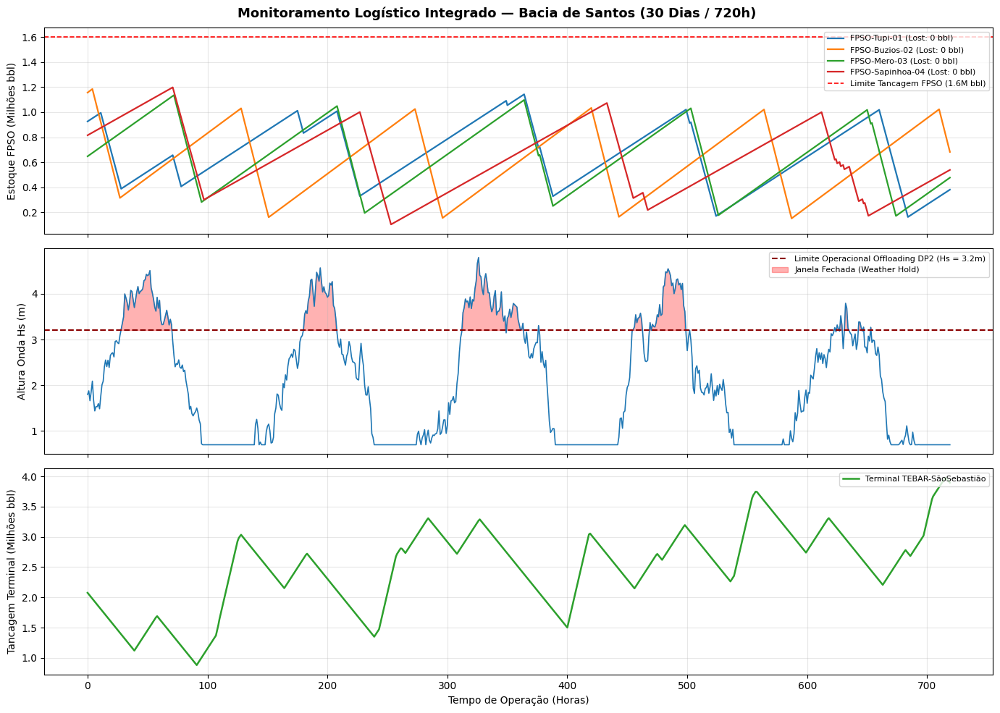

In [ ]:
# AUTOR : MARCELO DE OLIVEIRA SANTOS JUNIOR
# Orquestrador da Operação (4 FPSOs, 3 Navios Aliviadores, 1 Terminal)

# Removidas as importações do pacote 'src' aqui no colab não funcionou as importações


def run_simulation() -> None:
    fpsos = [
        FPSO("FPSO-Tupi-01", -25.45, -42.85, 2120, 1_600_000, 920_000, 6_250, 42_000),
        FPSO("FPSO-Buzios-02", -24.90, -42.50, 1980, 1_600_000, 1_150_000, 7_100, 45_000),
        FPSO("FPSO-Mero-03", -24.65, -42.35, 2050, 1_600_000, 640_000, 6_800, 44_000),
        FPSO("FPSO-Sapinhoa-04", -25.70, -43.10, 2140, 1_600_000, 810_000, 5_400, 40_000),
    ]

    tankers = [
        ShuttleTanker("ST-Brasil-Alpha", 1_050_000, 13.5, 48_000, 95.0, -23.82, -45.38),
        ShuttleTanker("ST-Santos-Beta", 1_050_000, 14.0, 51_000, 102.0, -25.10, -43.50),
        ShuttleTanker("ST-Atlantic-Gamma", 1_050_000, 13.0, 46_500, 90.0, -24.20, -44.60),
    ]

    terminal = CoastalTerminal(
        name="TEBAR-SãoSebastião",
        lat=-23.81,
        lon=-45.39,
        storage_capacity_bbl=6_500_000,
        current_inventory_bbl=2_100_000,
        pipeline_outflow_bph=24_500,
        max_discharge_rate_bph=55_000,
    )

    metocean = MetoceanSimulator(hours=720, seed=42)
    engine = OffshoreLogisticsEngine(fpsos, tankers, terminal, metocean)

    for hour in range(720):
        engine.step(hour)

    print("=== RESUMO OPERACIONAL (30 DIAS) ===")
    total_cost = sum(t.total_cost_usd for t in tankers)
    total_lost = sum(f.total_lost_bbl for f in fpsos)
    for f in fpsos:
        print(f"{f.name:<18} | Shut-in: {f.shut_in_hours:>3}h | Produção Perdida: {f.total_lost_bbl:>10,.0f} bbl")
    print(f"\nCusto Total Afretamento + Combustível Frota: US$ {total_cost:,.2f}")
    print(f"Perda Total por Restrição Logística/Clima:   {total_lost:,.0f} bbl")

    render_2d_operations_dashboard(fpsos, terminal, metocean)
    render_4d_offshore_network(fpsos, tankers, terminal)


if __name__ == "__main__":
    run_simulation()

=== RESUMO OPERACIONAL (30 DIAS) ===
FPSO-Tupi-01       | Shut-in:   0h | Produção Perdida:          0 bbl
FPSO-Buzios-02     | Shut-in:   0h | Produção Perdida:          0 bbl
FPSO-Mero-03       | Shut-in:   0h | Produção Perdida:          0 bbl
FPSO-Sapinhoa-04   | Shut-in:   0h | Produção Perdida:          0 bbl

Custo Total Afretamento + Combustível Frota: US$ 4,987,857.82
Perda Total por Restrição Logística/Clima:   0 bbl


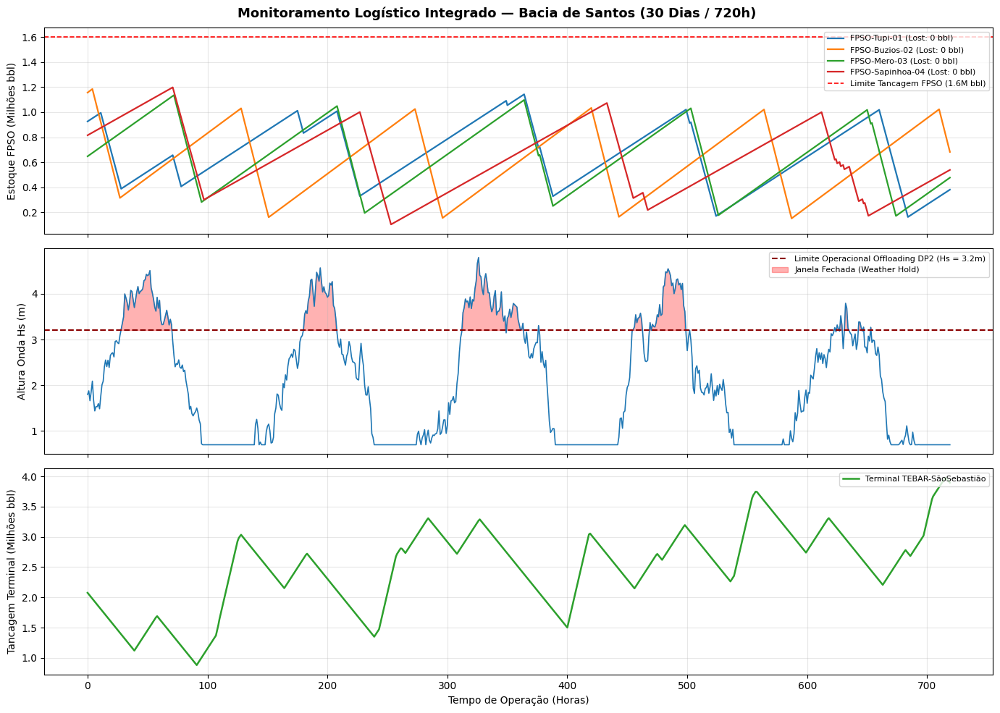

In [11]:
# AUTOR : MARCELO DE OLIVEIRA SANTOS JUNIOR
# Orquestrador da Operação (4 FPSOs, 3 Navios Aliviadores, 1 Terminal)

# Removidas as importações do pacote 'src' aqui no colab não funcionou as importações


def run_simulation() -> None:
    fpsos = [
        FPSO("FPSO-Tupi-01", -25.45, -42.85, 2120, 1_600_000, 920_000, 6_250, 42_000),
        FPSO("FPSO-Buzios-02", -24.90, -42.50, 1980, 1_600_000, 1_150_000, 7_100, 45_000),
        FPSO("FPSO-Mero-03", -24.65, -42.35, 2050, 1_600_000, 640_000, 6_800, 44_000),
        FPSO("FPSO-Sapinhoa-04", -25.70, -43.10, 2140, 1_600_000, 810_000, 5_400, 40_000),
    ]

    tankers = [
        ShuttleTanker("ST-Brasil-Alpha", 1_050_000, 13.5, 48_000, 95.0, -23.82, -45.38),
        ShuttleTanker("ST-Santos-Beta", 1_050_000, 14.0, 51_000, 102.0, -25.10, -43.50),
        ShuttleTanker("ST-Atlantic-Gamma", 1_050_000, 13.0, 46_500, 90.0, -24.20, -44.60),
    ]

    terminal = CoastalTerminal(
        name="TEBAR-SãoSebastião",
        lat=-23.81,
        lon=-45.39,
        storage_capacity_bbl=6_500_000,
        current_inventory_bbl=2_100_000,
        pipeline_outflow_bph=24_500,
        max_discharge_rate_bph=55_000,
    )

    metocean = MetoceanSimulator(hours=720, seed=42)
    engine = OffshoreLogisticsEngine(fpsos, tankers, terminal, metocean)

    for hour in range(720):
        engine.step(hour)

    print("=== RESUMO OPERACIONAL (30 DIAS) ===")
    total_cost = sum(t.total_cost_usd for t in tankers)
    total_lost = sum(f.total_lost_bbl for f in fpsos)
    for f in fpsos:
        print(f"{f.name:<18} | Shut-in: {f.shut_in_hours:>3}h | Produção Perdida: {f.total_lost_bbl:>10,.0f} bbl")
    print(f"\nCusto Total Afretamento + Combustível Frota: US$ {total_cost:,.2f}")
    print(f"Perda Total por Restrição Logística/Clima:   {total_lost:,.0f} bbl")

    render_2d_operations_dashboard(fpsos, terminal, metocean)
    render_4d_offshore_network(fpsos, tankers, terminal)


if __name__ == "__main__":
    run_simulation()

In [15]:
# AUTOR : MARCELO DE OLIVEIRA SANTOS JUNIOR
# Testes Unitários (verificação)

# IMPORTANTE: Se ocorrer o erro "NameError: name 'OffshoreLogisticsEngine' is not defined",
# certifique-se de executar as células anteriores do notebook primeiro (especialmente a célula 5AnSLGt4-mZI)
# para carregar as definições das classes na memória do Colab.

def test_weather_hold_prevents_offloading():
    fpso = FPSO("FPSO-Test", -25.0, -43.0, 2000, 1_600_000, 1_200_000, 5_000, 40_000, max_wave_height_m=3.0)
    tanker = ShuttleTanker("ST-Test", 1_000_000, 14.0, 45_000, 90.0, -25.0, -43.0, status="OFFLOADING", target_name="FPSO-Test")
    terminal = CoastalTerminal("TEBAR", -23.8, -45.4, 5_000_000, 1_000_000, 20_000, 50_000)

    metocean = MetoceanSimulator(hours=10)
    metocean.wave_height_m[0] = 4.5  # Tempestade acima do limite de 3.0m

    engine = OffshoreLogisticsEngine([fpso], [tanker], terminal, metocean)
    engine.step(0)

    assert tanker.cargo_bbl == 0.0
    assert tanker.route_history[-1][-1] == "WEATHER_HOLD"

# Executa o teste unitário após garantir que as classes existam na memória
try:
    test_weather_hold_prevents_offloading()
    print("Teste executado com sucesso e passou!")
except NameError as e:
    print(f"Erro de Execução: {e}")
    print("Por favor, execute as células anteriores do notebook (de cima para baixo) para carregar as classes na memória antes de rodar os testes!")

Teste executado com sucesso e passou!
